Library version is 3.0

Mode             : 2
Binning           : 8
Offset            : 0
AcquisitionTime   : 25000
SyncDivider       : 1
SyncCFDZeroCross  : 10
SyncCFDLevel      : 50
InputCFDZeroCross : 10
InputCFDLevel     : 50

Searching for HydraHarp devices...
Devidx     Status
  0        S/N 1011000
  1        no device
  2        no device
  3        no device
  4        no device
  5        no device
  6        no device
  7        no device
Using device #0

Initializing the device...
Found Model HydraHarp 400 Part no 930010 Version 2.0
Device has 4 input channels.

Calibrating...

Syncrate=625560/s
Countrate[0]=840840/s
Countrate[1]=0/s
Countrate[2]=0/s
Countrate[3]=0/s

Progress:        0
Progress:        0

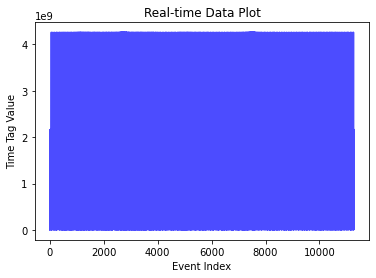

Progress:  1846295
FiFo Overrun!


SystemExit: 0

In [4]:

import time
import ctypes as ct
from ctypes import byref
import sys
import os
import matplotlib.pyplot as plt
import numpy as np

# From hhdefin.h
LIB_VERSION   = "3.0"
MAXDEVNUM     = 8
MODE_T2       = 2
MODE_T3       = 3
MAXLENCODE    = 6
HHMAXINPCHAN  = 8
TTREADMAX     = 131072
FLAG_OVERFLOW = 0x0001
FLAG_FIFOFULL = 0x0002

# Measurement parameters, these are hardcoded since this is just a demo
mode               = MODE_T2 # Set T2 or T3 here, observe suitable Syncdivider and Range!
binning            = 8 # You can change this, meaningful only in T3 mode
offset             = 0 # You can change this, meaningful only in T3 mode
tacq               = 25000 # Measurement time in millisec, you can change this
syncDivider        = 1 # You can change this, observe mode! READ MANUAL!
syncCFDZeroCross   = 10 # You can change this (in mV)
syncCFDLevel       = 50 # You can change this (in mV)
syncChannelOffset  = -5000 # You can change this (in ps, like a cable delay)
inputCFDZeroCross  = 10 # You can change this (in mV)
inputCFDLevel      = 50 # You can change this (in mV)
inputChannelOffset = 0 # You can change this (in ps, like a cable delay)

# Variables to store information read from DLLs
buffer       = (ct.c_uint * TTREADMAX)()
dev          = []
libVersion   = ct.create_string_buffer(b"", 8)
hwSerial     = ct.create_string_buffer(b"", 8)
hwPartno     = ct.create_string_buffer(b"", 8)
hwVersion    = ct.create_string_buffer(b"", 8)
hwModel      = ct.create_string_buffer(b"", 16)
errorString  = ct.create_string_buffer(b"", 40)
numChannels  = ct.c_int()
resolution   = ct.c_double()
syncRate     = ct.c_int()
countRate    = ct.c_int()
flags        = ct.c_int()
nRecords     = ct.c_int()
ctcstatus    = ct.c_int()
warnings     = ct.c_int()
warningstext = ct.create_string_buffer(b"", 16384)

if os.name == "nt":
    hhlib = ct.WinDLL("hhlib.dll")
else:
    hhlib = ct.CDLL("libhh400.so")

def closeDevices():
    for i in range(0, MAXDEVNUM):
        hhlib.HH_CloseDevice(ct.c_int(i))
    sys.exit(0)

def stoptttr():
    retcode = hhlib.HH_StopMeas(ct.c_int(dev[0]))
    if retcode < 0:
        print("HH_StopMeas error %1d. Aborted." % retcode)
    closeDevices()

def tryfunc(retcode, funcName, measRunning=False):
    if retcode < 0:
        hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
        print("HH_%s error %d (%s). Aborted." % (funcName, retcode,\
              errorString.value.decode("utf-8")))
        if measRunning:
            stoptttr()
        else:
            closeDevices()

hhlib.HH_GetLibraryVersion(libVersion)
print("Library version is %s" % libVersion.value.decode("utf-8"))
if libVersion.value.decode("utf-8") != LIB_VERSION:
    print("Warning: The application was built for version %s" % LIB_VERSION)



print("\nMode             : %d" % mode)
print("Binning           : %d" % binning)
print("Offset            : %d" % offset)
print("AcquisitionTime   : %d" % tacq)
print("SyncDivider       : %d" % syncDivider)
print("SyncCFDZeroCross  : %d" % syncCFDZeroCross)
print("SyncCFDLevel      : %d" % syncCFDLevel)
print("InputCFDZeroCross : %d" % inputCFDZeroCross)
print("InputCFDLevel     : %d" % inputCFDLevel)

print("\nSearching for HydraHarp devices...")
print("Devidx     Status")

for i in range(0, MAXDEVNUM):
    retcode = hhlib.HH_OpenDevice(ct.c_int(i), hwSerial)
    if retcode == 0:
        print("  %1d        S/N %s" % (i, hwSerial.value.decode("utf-8")))
        dev.append(i)
    else:
        if retcode == -1: # HH_ERROR_DEVICE_OPEN_FAIL
            print("  %1d        no device" % i)
        else:
            hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
            print("  %1d        %s" % (i, errorString.value.decode("utf8")))

# In this demo we will use the first HydraHarp device we find, i.e. dev[0].
# You can also use multiple devices in parallel.
# You can also check for specific serial numbers, so that you always know
# which physical device you are talking to.

if len(dev) < 1:
    print("No device available.")
    closeDevices()
print("Using device #%1d" % dev[0])
print("\nInitializing the device...")

# With internal clock
tryfunc(hhlib.HH_Initialize(ct.c_int(dev[0]), ct.c_int(mode), ct.c_int(0)),\
        "Initialize")

# Only for information
tryfunc(hhlib.HH_GetHardwareInfo(dev[0], hwModel, hwPartno, hwVersion),\
        "GetHardwareInfo")
print("Found Model %s Part no %s Version %s" % (hwModel.value.decode("utf-8"),\
      hwPartno.value.decode("utf-8"), hwVersion.value.decode("utf-8")))

tryfunc(hhlib.HH_GetNumOfInputChannels(ct.c_int(dev[0]), byref(numChannels)),\
        "GetNumOfInputChannels")
print("Device has %i input channels." % numChannels.value)

print("\nCalibrating...")
tryfunc(hhlib.HH_Calibrate(ct.c_int(dev[0])), "Calibrate")
tryfunc(hhlib.HH_SetSyncDiv(ct.c_int(dev[0]), ct.c_int(syncDivider)), "SetSyncDiv")

tryfunc(hhlib.HH_SetSyncCFD(ct.c_int(dev[0]), ct.c_int(syncCFDLevel),
                            ct.c_int(syncCFDZeroCross)),\
        "SetSyncCFD")

tryfunc(hhlib.HH_SetSyncChannelOffset(ct.c_int(dev[0]), ct.c_int(syncChannelOffset)),\
        "SetSyncChannelOffset")

# We use the same input settings for all channels, you can change this
for i in range(0, numChannels.value):
    tryfunc(hhlib.HH_SetInputCFD(ct.c_int(dev[0]), ct.c_int(i), ct.c_int(inputCFDLevel),\
                                 ct.c_int(inputCFDZeroCross)),\
            "SetInputCFD")

    tryfunc(hhlib.HH_SetInputChannelOffset(ct.c_int(dev[0]), ct.c_int(i),\
                                           ct.c_int(inputChannelOffset)),\
            "SetInputChannelOffset")


# Note: After Init or SetSyncDiv you must allow >100 ms for valid  count rate readings
time.sleep(0.4)

tryfunc(hhlib.HH_GetSyncRate(ct.c_int(dev[0]), byref(syncRate)), "GetSyncRate")
print("\nSyncrate=%1d/s" % syncRate.value)

for i in range(0, numChannels.value):
    tryfunc(hhlib.HH_GetCountRate(ct.c_int(dev[0]), ct.c_int(i), byref(countRate)),\
            "GetCountRate")
    print("Countrate[%1d]=%1d/s" % (i, countRate.value))

progress = 0
sys.stdout.write("\nProgress:%9u" % progress)
sys.stdout.flush()

tryfunc(hhlib.HH_StartMeas(ct.c_int(dev[0]), ct.c_int(tacq)), "StartMeas")

plt.ion()
fig, ax = plt.subplots()
x_data = []
y_data = []

progress = 0
sys.stdout.write("\nProgress:%9u" % progress)
sys.stdout.flush()

tryfunc(hhlib.HH_StartMeas(ct.c_int(dev[0]), ct.c_int(tacq)), "StartMeas")

while True:
    tryfunc(hhlib.HH_GetFlags(ct.c_int(dev[0]), byref(flags)), "GetFlags")

    if flags.value & FLAG_FIFOFULL > 0:
        print("\nFiFo Overrun!")
        stoptttr()

    tryfunc(hhlib.HH_ReadFiFo(ct.c_int(dev[0]), byref(buffer), TTREADMAX, byref(nRecords)), "ReadFiFo", measRunning=True)

    if nRecords.value > 0:
        # Convert buffer to a NumPy array
        new_data = np.array(buffer[:nRecords.value], dtype=np.uint32)

        # Append to the existing data
        x_data.extend(range(len(y_data), len(y_data) + len(new_data)))
        y_data.extend(new_data)

        # Update the plot dynamically
        ax.clear()
        ax.plot(x_data, y_data, 'b-', alpha=0.7)
        ax.set_xlabel("Event Index")
        ax.set_ylabel("Time Tag Value")
        ax.set_title("Real-time Data Plot")
        plt.pause(0.01)  # Pause to refresh the plot

        progress += nRecords.value
        sys.stdout.write("\rProgress:%9u" % progress)
        sys.stdout.flush()
    else:
        tryfunc(hhlib.HH_CTCStatus(ct.c_int(dev[0]), byref(ctcstatus)), "CTCStatus")
        if ctcstatus.value > 0:
            print("\nDone")
            stoptttr()
            break  # Exit loop when measurement is complete

# Close devices and finalize the plot
closeDevices()
plt.ioff()
plt.show()  # Show final plot after measurement ends
# while True:
#     tryfunc(hhlib.HH_GetFlags(ct.c_int(dev[0]), byref(flags)), "GetFlags")
#
#     if flags.value & FLAG_FIFOFULL > 0:
#         print("\nFiFo Overrun!")
#         stoptttr()
#
#     tryfunc(hhlib.HH_ReadFiFo(ct.c_int(dev[0]), byref(buffer), TTREADMAX,\
#                               byref(nRecords)),\
#             "ReadFiFo", measRunning=True)
#
#     if nRecords.value > 0:
#         # We could just iterate through our buffer with a for loop, however,
#         # this is slow and might cause a FIFO overrun. So instead, we shrinken
#         # the buffer to its appropriate length with array slicing, which gives
#         # us a python list. This list then needs to be converted back into
#         # a ctype array which can be written at once to the output file
#         output = (ct.c_uint*nRecords.value)(*buffer[0:nRecords.value])
#         plt.plot(output)
#         plt.show(output)
#
#         progress += nRecords.value
#         sys.stdout.write("\rProgress:%9u" % progress)
#         sys.stdout.flush()
#     else:
#         tryfunc(hhlib.HH_CTCStatus(ct.c_int(dev[0]), byref(ctcstatus)),\
#                 "CTCStatus")
#         if ctcstatus.value > 0:
#             print("\nDone")
#             stoptttr()
#     # Within this loop you can also read the count rates if needed.
## closeDevices()

In [26]:
    for k in range(len(output)):
    print(output[k])



4261412866
2154874395
2168286899
4261412865
2155139323
13760948
4261412867
2162728490
4261412865
2173720826
4261412865
13027058
2173823826
4261412865
13346972
4261412866
2247853
23681732
4261412866
2154246272
2157166684
2158252422
2166898774
2167019839
2171064287
23895445
2172110457
4261412865
7762694
2178335475
4261412865
2160152826
4261412865
6553709
10571308
4261412865
2180946890
4261412865
6576220
4261412865
2151964658
2152947977
2153165011
2154470246
2169430507
4261412866
2170208152
4261412866
2168934801
4261412865
2150350986
26292874
4261412865
28186923
32473923
4261412866
19596916
21407880
4261412865
7035265
2165200041
27775763
4261412866
2160925681
4261412865
18611344
4261412865
2159279554
4261412867
2162820357
4261412867
2147709605
4261412865
2156121310
4261412865
16317508
4261412866
2176962772
4261412867
2174436846
4261412865
2153111453
17677371
2178851495
4261412866
2159840129
2160080894
16450057
4261412866
23719328
4261412865
24998886
2175589223
4261412866
148021
2157391584

In [1]:


import time
import ctypes as ct
from ctypes import byref
import sys
import os


# From hhdefin.h
LIB_VERSION   = "3.0"
MAXDEVNUM     = 8
MODE_T2       = 2
MODE_T3       = 3
MAXLENCODE    = 6
HHMAXINPCHAN  = 8
TTREADMAX     = 131072
FLAG_OVERFLOW = 0x0001
FLAG_FIFOFULL = 0x0002

# Measurement parameters, these are hardcoded since this is just a demo
mode               = MODE_T2 # Set T2 or T3 here, observe suitable Syncdivider and Range!
binning            = 0 # You can change this, meaningful only in T3 mode
offset             = 0 # You can change this, meaningful only in T3 mode
tacq               = 250 # Measurement time in millisec, you can change this
syncDivider        = 1 # You can change this, observe mode! READ MANUAL!
syncCFDZeroCross   = 10 # You can change this (in mV)
syncCFDLevel       = 50 # You can change this (in mV)
syncChannelOffset  = -5000 # You can change this (in ps, like a cable delay)
inputCFDZeroCross  = 10 # You can change this (in mV)
inputCFDLevel      = 50 # You can change this (in mV)
inputChannelOffset = 0 # You can change this (in ps, like a cable delay)

# Variables to store information read from DLLs
buffer       = (ct.c_uint * TTREADMAX)()
dev          = []
libVersion   = ct.create_string_buffer(b"", 8)
hwSerial     = ct.create_string_buffer(b"", 8)
hwPartno     = ct.create_string_buffer(b"", 8)
hwVersion    = ct.create_string_buffer(b"", 8)
hwModel      = ct.create_string_buffer(b"", 16)
errorString  = ct.create_string_buffer(b"", 40)
numChannels  = ct.c_int()
resolution   = ct.c_double()
syncRate     = ct.c_int()
countRate    = ct.c_int()
flags        = ct.c_int()
nRecords     = ct.c_int()
ctcstatus    = ct.c_int()
warnings     = ct.c_int()
warningstext = ct.create_string_buffer(b"", 16384)

if os.name == "nt":
    hhlib = ct.WinDLL("hhlib.dll")
else:
    hhlib = ct.CDLL("libhh400.so")

def closeDevices():
    for i in range(0, MAXDEVNUM):
        hhlib.HH_CloseDevice(ct.c_int(i))
    sys.exit(0)

def stoptttr():
    retcode = hhlib.HH_StopMeas(ct.c_int(dev[0]))
    if retcode < 0:
        print("HH_StopMeas error %1d. Aborted." % retcode)
    closeDevices()

def tryfunc(retcode, funcName, measRunning=False):
    if retcode < 0:
        hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
        print("HH_%s error %d (%s). Aborted." % (funcName, retcode,\
              errorString.value.decode("utf-8")))
        if measRunning:
            stoptttr()
        else:
            closeDevices()

hhlib.HH_GetLibraryVersion(libVersion)
print("Library version is %s" % libVersion.value.decode("utf-8"))
if libVersion.value.decode("utf-8") != LIB_VERSION:
    print("Warning: The application was built for version %s" % LIB_VERSION)

outputfile = open("tttrmode.ptu", "wb+")

print("\nMode             : %d" % mode)
print("Binning           : %d" % binning)
print("Offset            : %d" % offset)
print("AcquisitionTime   : %d" % tacq)
print("SyncDivider       : %d" % syncDivider)
print("SyncCFDZeroCross  : %d" % syncCFDZeroCross)
print("SyncCFDLevel      : %d" % syncCFDLevel)
print("InputCFDZeroCross : %d" % inputCFDZeroCross)
print("InputCFDLevel     : %d" % inputCFDLevel)

print("\nSearching for HydraHarp devices...")
print("Devidx     Status")

for i in range(0, MAXDEVNUM):
    retcode = hhlib.HH_OpenDevice(ct.c_int(i), hwSerial)
    if retcode == 0:
        print("  %1d        S/N %s" % (i, hwSerial.value.decode("utf-8")))
        dev.append(i)
    else:
        if retcode == -1: # HH_ERROR_DEVICE_OPEN_FAIL
            print("  %1d        no device" % i)
        else:
            hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
            print("  %1d        %s" % (i, errorString.value.decode("utf8")))

# In this demo we will use the first HydraHarp device we find, i.e. dev[0].
# You can also use multiple devices in parallel.
# You can also check for specific serial numbers, so that you always know
# which physical device you are talking to.

if len(dev) < 1:
    print("No device available.")
    closeDevices()
print("Using device #%1d" % dev[0])
print("\nInitializing the device...")

# With internal clock
tryfunc(hhlib.HH_Initialize(ct.c_int(dev[0]), ct.c_int(mode), ct.c_int(0)),\
        "Initialize")

# Only for information
tryfunc(hhlib.HH_GetHardwareInfo(dev[0], hwModel, hwPartno, hwVersion),\
        "GetHardwareInfo")
print("Found Model %s Part no %s Version %s" % (hwModel.value.decode("utf-8"),\
      hwPartno.value.decode("utf-8"), hwVersion.value.decode("utf-8")))

tryfunc(hhlib.HH_GetNumOfInputChannels(ct.c_int(dev[0]), byref(numChannels)),\
        "GetNumOfInputChannels")
print("Device has %i input channels." % numChannels.value)

print("\nCalibrating...")
tryfunc(hhlib.HH_Calibrate(ct.c_int(dev[0])), "Calibrate")
tryfunc(hhlib.HH_SetSyncDiv(ct.c_int(dev[0]), ct.c_int(syncDivider)), "SetSyncDiv")

tryfunc(hhlib.HH_SetSyncCFD(ct.c_int(dev[0]), ct.c_int(syncCFDLevel),
                            ct.c_int(syncCFDZeroCross)),\
        "SetSyncCFD")

tryfunc(hhlib.HH_SetSyncChannelOffset(ct.c_int(dev[0]), ct.c_int(syncChannelOffset)),\
        "SetSyncChannelOffset")

# We use the same input settings for all channels, you can change this
for i in range(0, numChannels.value):
    tryfunc(hhlib.HH_SetInputCFD(ct.c_int(dev[0]), ct.c_int(i), ct.c_int(inputCFDLevel),\
                                 ct.c_int(inputCFDZeroCross)),\
            "SetInputCFD")

    tryfunc(hhlib.HH_SetInputChannelOffset(ct.c_int(dev[0]), ct.c_int(i),\
                                           ct.c_int(inputChannelOffset)),\
            "SetInputChannelOffset")

# Meaningful only in T3 mode
if mode == MODE_T3:
    tryfunc(hhlib.HH_SetBinning(ct.c_int(dev[0]), ct.c_int(binning)), "SetBinning")
    tryfunc(hhlib.HH_SetOffset(ct.c_int(dev[0]), ct.c_int(offset)), "SetOffset")
    tryfunc(hhlib.HH_GetResolution(ct.c_int(dev[0]), byref(resolution)), "GetResolution")
    print("Resolution is %1.1lfps" % resolution.value)

# Note: After Init or SetSyncDiv you must allow >100 ms for valid  count rate readings
time.sleep(0.4)

tryfunc(hhlib.HH_GetSyncRate(ct.c_int(dev[0]), byref(syncRate)), "GetSyncRate")
print("\nSyncrate=%1d/s" % syncRate.value)

for i in range(0, numChannels.value):
    tryfunc(hhlib.HH_GetCountRate(ct.c_int(dev[0]), ct.c_int(i), byref(countRate)),\
            "GetCountRate")
    print("Countrate[%1d]=%1d/s" % (i, countRate.value))

progress = 0
sys.stdout.write("\nProgress:%9u" % progress)
sys.stdout.flush()

tryfunc(hhlib.HH_StartMeas(ct.c_int(dev[0]), ct.c_int(tacq)), "StartMeas")

while True:
    tryfunc(hhlib.HH_GetFlags(ct.c_int(dev[0]), byref(flags)), "GetFlags")

    if flags.value & FLAG_FIFOFULL > 0:
        print("\nFiFo Overrun!")
        stoptttr()

    tryfunc(hhlib.HH_ReadFiFo(ct.c_int(dev[0]), byref(buffer), TTREADMAX,\
                              byref(nRecords)),\
            "ReadFiFo", measRunning=True)

    if nRecords.value > 0:
        # We could just iterate through our buffer with a for loop, however,
        # this is slow and might cause a FIFO overrun. So instead, we shrinken
        # the buffer to its appropriate length with array slicing, which gives
        # us a python list. This list then needs to be converted back into
        # a ctype array which can be written at once to the output file
        outputfile.write((ct.c_uint*nRecords.value)(*buffer[0:nRecords.value]))
        progress += nRecords.value
        sys.stdout.write("\rProgress:%9u" % progress)
        sys.stdout.flush()
    else:
        tryfunc(hhlib.HH_CTCStatus(ct.c_int(dev[0]), byref(ctcstatus)),\
                "CTCStatus")
        if ctcstatus.value > 0:
            print("\nDone")
            stoptttr()
    # Within this loop you can also read the count rates if needed.

closeDevices()
outputfile.close()

Library version is 3.0

Mode             : 2
Binning           : 0
Offset            : 0
AcquisitionTime   : 250
SyncDivider       : 1
SyncCFDZeroCross  : 10
SyncCFDLevel      : 50
InputCFDZeroCross : 10
InputCFDLevel     : 50

Searching for HydraHarp devices...
Devidx     Status
  0        S/N 1011000
  1        no device
  2        no device
  3        no device
  4        no device
  5        no device
  6        no device
  7        no device
Using device #0

Initializing the device...
Found Model HydraHarp 400 Part no 930010 Version 2.0
Device has 4 input channels.

Calibrating...

Syncrate=7887480/s
Countrate[0]=9129160/s
Countrate[1]=0/s
Countrate[2]=0/s
Countrate[3]=0/s

Progress:  1930050
Done


SystemExit: 0

C:\Users\photonbec\AppData\Local\Programs\Python\Python38-32\lib\site-packages\IPython\core\interactiveshell.py:3426: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [9]:


import time
import ctypes as ct
from ctypes import byref
import sys
import os
import struct


# From hhdefin.h
LIB_VERSION   = "3.0"
MAXDEVNUM     = 8
MODE_T2       = 2
MODE_T3       = 3
MAXLENCODE    = 6
HHMAXINPCHAN  = 8
TTREADMAX     = 131072
FLAG_OVERFLOW = 0x0001
FLAG_FIFOFULL = 0x0002

# Measurement parameters, these are hardcoded since this is just a demo
mode               = MODE_T2 # This demo is only for T3! Observe suitable Sync divider and Range!
binning            = 0 # You can change this, meaningful only in T3 mode
offset             = 0 # You can change this, meaningful only in T3 mode
tacq               = 500 # Measurement time in millisec, you can change this
syncDivider        = 1 # You can change this, observe mode! READ MANUAL!
syncCFDZeroCross   = 10 # You can change this (in mV)
syncCFDLevel       = 50 # You can change this (in mV)
syncChannelOffset  = 0 # You can change this (in ps, like a cable delay)
inputCFDZeroCross  = 10 # You can change this (in mV)
inputCFDLevel      = 50 # You can change this (in mV)
inputChannelOffset = 5000 # You can change this (in ps, like a cable delay)

# Variables to store information read from the DLL
buffer        = (ct.c_uint * TTREADMAX)()
dev           = []
libVersion    = ct.create_string_buffer(b"", 8)
hwSerial      = ct.create_string_buffer(b"", 8)
hwPartno      = ct.create_string_buffer(b"", 8)
hwVersion     = ct.create_string_buffer(b"", 8)
hwModel       = ct.create_string_buffer(b"", 16)
errorString   = ct.create_string_buffer(b"", 40)
numChannels   = ct.c_int()
resolution    = ct.c_double(0) # in ps
syncRate      = ct.c_int()
syncPeriod    = ct.c_double(0)
countRate     = ct.c_int()
flags         = ct.c_int()
recNum        = ct.c_int()
nRecords      = ct.c_int()
ctcstatus     = ct.c_int()
warnings      = ct.c_int()
warningstext  = ct.create_string_buffer(b"", 16384)
timeTag       = ct.c_int()
channel       = ct.c_int()
markers       = ct.c_int()
dTime         = ct.c_int()
special       = ct.c_int()
oflcorrection = ct.c_int()
progress      = ct.c_int()

# Define PTU File Structure
PTU_HEADER_ENTRIES = [
    ("CreatorSW", "SoftwareName"),    # Software name
    ("FileTime", int(time.time())),   # Creation timestamp
    ("Version", "1.0.0"),             # PTU format version
    ("MeasurementMode", 2),           # Mode 2 = T2 mode
    ("TTResult_NumberOfRecords", 0),  # Placeholder for record count
]

# Open PTU file in binary mode
outputfile = open("tttrmodeout.ptu", "wb")

# Write PTU Header
def write_ptu_header(file):
    """Writes a valid PTU header"""
    for tag, value in PTU_HEADER_ENTRIES:
        tag_name = tag.ljust(32, '\0').encode("utf-8")  # Ensure 32-byte tag name
        file.write(tag_name)
        if isinstance(value, int):
            file.write(struct.pack("<i", 0x00010000))  # Value type for int
            file.write(struct.pack("<q", value))       # 64-bit integer value
        else:
            file.write(struct.pack("<i", 0x00000008))  # Value type for string
            value_bytes = value.encode("utf-8") + b"\0"
            file.write(value_bytes.ljust(16, b"\0"))   # 16-byte fixed length

write_ptu_header(outputfile)

# Modify Photon Event Processing to Binary
def GotPhotonT2(timeTag, channel):
    """Write T2 Photon Event in PTU Format"""
    global outputfile
    record = struct.pack("<II", timeTag, channel)  # Binary format: timeTag, channel
    outputfile.write(record)

def GotMarkerT2(timeTag, markers):
    """Write T2 Marker Event in PTU Format"""
    global outputfile
    record = struct.pack("<II", timeTag, markers | 0x80000000)  # Markers have MSB set
    outputfile.write(record)



# ProcessT2
# HydraHarpV2 or TimeHarp260 or MultiHarp T2 record data
def ProcessT2(TTTRRecord):
    global recNum, nRecords, oflcorrection, markers, channel, special
    ch = 0
    truetime = 0
    T2WRAPAROUND_V2 = 33554432
    try:
        # The data handed out to this function is transformed to an up to 32 digits long binary number
        # and this binary is filled by zeros from the left up to 32 bit.
        recordDatabinary = '{0:0{1}b}'.format(TTTRRecord,32)
    except:
        print("\nThe file ended earlier than expected, at record %d/%d."\
          % (recNum.value, nRecords.value))
        sys.exit(0)

    # Then the different parts of this 32 bit are splitted and handed over to the Variables
    special = int(recordDatabinary[0:1], base=2) # 1 bit for special
    channel = int(recordDatabinary[1:7], base=2) # 6 bits for channel
    timeTag = int(recordDatabinary[7:32], base=2) # 25 bits for timeTag


    if special==1:
        if channel == 0x3F: # Special record, including Overflow as well as markers and Sync
            # Number of overflows is stored in timeTag
            oflcorrection.value += T2WRAPAROUND_V2 * timeTag
        if channel>=1 and channel<=15: # markers
            truetime = oflcorrection.value + T2WRAPAROUND_V2 * timeTag
            # Note that actual marker tagging accuracy is only some ns
            ch = channel
            GotMarkerT2(truetime, ch)
        if channel==0: # Sync
            truetime = oflcorrection.value + timeTag
            ch = 0 # We encode the sync channel as 0
            GotPhotonT2(truetime, ch)
    else: # Regular input channel
        truetime = oflcorrection.value + timeTag
        ch = channel + 1 # We encode the regular channels as 1..N
        GotPhotonT2(truetime, ch)

# ProcessT3
# HydraHarpV2 or TimeHarp260 or MultiHarp T3 record data


if os.name == "nt":
    hhlib = ct.WinDLL("hhlib.dll")
else:
    hhlib = ct.CDLL("libhh400.so")

def closeDevices():
    for i in range(0, MAXDEVNUM):
        hhlib.HH_CloseDevice(ct.c_int(i))
    sys.exit(0)

def stoptttr():
    retcode = hhlib.HH_StopMeas(ct.c_int(dev[0]))
    if retcode < 0:
        print("HH_StopMeas error %1d. Aborted." % retcode)
    closeDevices()

def tryfunc(retcode, funcName, measRunning=False):
    if retcode < 0:
        hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
        print("HH_%s error %d (%s). Aborted." % (funcName, retcode,\
              errorString.value.decode("utf-8")))
        if measRunning:
            stoptttr()
        else:
            closeDevices()


hhlib.HH_GetLibraryVersion(libVersion)
print("Library version is %s" % libVersion.value.decode("utf-8"))
if libVersion.value.decode("utf-8") != LIB_VERSION:
    print("Warning: The application was built for version %s" % LIB_VERSION)

outputfile = open("tttrmodeout.txt", "w+")

print("\n")
print("Mode              : %d" % mode)
print("Binning           : %d" % binning)
print("Offset            : %d" % offset)
print("AcquisitionTime   : %d" % tacq)
print("SyncDivider       : %d" % syncDivider)
print("SyncCFDZeroCross  : %d" % syncCFDZeroCross)
print("SyncCFDLevel      : %d" % syncCFDLevel)
print("InputCFDZeroCross : %d" % inputCFDZeroCross)
print("InputCFDLevel     : %d" % inputCFDLevel)

print("\nSearching for HydraHarp devices...")
print("Devidx     Status")

for i in range(0, MAXDEVNUM):
    retcode = hhlib.HH_OpenDevice(ct.c_int(i), hwSerial)
    if retcode == 0:
        print("  %1d        S/N %s" % (i, hwSerial.value.decode("utf-8")))
        dev.append(i)
    else:
        if retcode == -1: # HH_ERROR_DEVICE_OPEN_FAIL
            print("  %1d        no device" % i)
        else:
            hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
            print("  %1d        %s" % (i, errorString.value.decode("utf8")))

# In this demo we will use the first HydraHarp device we find, i.e. dev[0].
# You can also use multiple devices in parallel.
# You can also check for specific serial numbers, so that you always know
# which physical device you are talking to.

if len(dev) < 1:
    print("No device available.")
    closeDevices()
print("Using device #%1d" % dev[0])
print("\nInitializing the device...")

# With internal clock
tryfunc(hhlib.HH_Initialize(ct.c_int(dev[0]), ct.c_int(mode), ct.c_int(0)),\
        "Initialize")

# Only for information
tryfunc(hhlib.HH_GetHardwareInfo(dev[0], hwModel, hwPartno, hwVersion),\
        "GetHardwareInfo")
print("Found Model %s Part no %s Version %s" % (hwModel.value.decode("utf-8"),\
      hwPartno.value.decode("utf-8"), hwVersion.value.decode("utf-8")))

tryfunc(hhlib.HH_GetNumOfInputChannels(ct.c_int(dev[0]), byref(numChannels)),\
        "GetNumOfInputchannels")
print("Device has %i input channels." % numChannels.value)

print("\nCalibrating...")
tryfunc(hhlib.HH_Calibrate(ct.c_int(dev[0])), "Calibrate")
tryfunc(hhlib.HH_SetSyncDiv(ct.c_int(dev[0]), ct.c_int(syncDivider)), "SetSyncDiv")

tryfunc(hhlib.HH_SetSyncCFD(ct.c_int(dev[0]), ct.c_int(syncCFDLevel),
                            ct.c_int(syncCFDZeroCross)),\
        "SetSyncCFD")

tryfunc(hhlib.HH_SetSyncChannelOffset(ct.c_int(dev[0]), ct.c_int(syncChannelOffset)),\
        "SetSyncChannelOffset")

# We use the same input settings for all channels, you can change this
for i in range(0, numChannels.value):
    tryfunc(hhlib.HH_SetInputCFD(ct.c_int(dev[0]), ct.c_int(i), ct.c_int(inputCFDLevel),\
                                 ct.c_int(inputCFDZeroCross)),\
            "SetInputCFD")

    tryfunc(hhlib.HH_SetInputChannelOffset(ct.c_int(dev[0]), ct.c_int(i),\
                                           ct.c_int(inputChannelOffset)),\
            "SetInputChannelOffset")

# Meaningful only in T3 mode
if mode == MODE_T3:
    tryfunc(hhlib.HH_SetBinning(ct.c_int(dev[0]), ct.c_int(binning)), "SetBinning")
    tryfunc(hhlib.HH_SetOffset(ct.c_int(dev[0]), ct.c_int(offset)), "SetOffset")

# Meaningful only in T3 mode
tryfunc(hhlib.HH_GetResolution(ct.c_int(dev[0]), byref(resolution)), "GetResolution")
print("Resolution is %1.1lfps" % resolution.value)

# Note: After Init or SetSyncDiv you must allow >100 ms for valid  count rate readings
time.sleep(0.2)

tryfunc(hhlib.HH_GetSyncRate(ct.c_int(dev[0]), byref(syncRate)), "GetSyncRate")
print("\nSyncrate=%1d/s" % syncRate.value)

for i in range(0, numChannels.value):
    tryfunc(hhlib.HH_GetCountRate(ct.c_int(dev[0]), ct.c_int(i), byref(countRate)),\
            "GetCountRate")
    print("Countrate[%1d]=%1d/s" % (i, countRate.value))

if mode == MODE_T2:
    outputfile.write("ev chn time/ps\n\n")
else:
    outputfile.write("ev chn   ttag/s   dtime/ps\n\n")



tryfunc(hhlib.HH_StartMeas(ct.c_int(dev[0]), ct.c_int(tacq)), "StartMeas")



print("\nStarting data collection...\n")


progress = 0
sys.stdout.write("\nProgress:%9u" % progress)
sys.stdout.flush()

tryfunc(hhlib.HH_StartMeas(ct.c_int(dev[0]), ct.c_int(tacq)), "StartMeas")

while True:
    tryfunc(hhlib.HH_GetFlags(ct.c_int(dev[0]), byref(flags)), "GetFlags")

    if flags.value & FLAG_FIFOFULL > 0:
        print("\nFiFo Overrun!")
        stoptttr()

    tryfunc(hhlib.HH_ReadFiFo(ct.c_int(dev[0]), byref(buffer), TTREADMAX,\
                              byref(nRecords)),\
            "ReadFiFo", measRunning=True)


    # Here we process the data. Note that the time this consumes prevents us
    # from getting around the loop quickly for the next Fifo read.
    # In a serious performance critical scenario you would write the data to
    # a software queue and do the processing in another thread reading from
    # that queue.
    if nRecords.value > 0:
        if mode == MODE_T2:
            for i in range(0, nRecords.value - 1):
                ProcessT2(buffer[i])
        else:
            for i in range(0, nRecords.value - 1):
                ProcessT3(buffer[i])

        progress += nRecords.value
        sys.stdout.write("\rProgress:%9u" % progress)
        sys.stdout.flush()
    else:
        tryfunc(hhlib.HH_CTCStatus(ct.c_int(dev[0]), byref(ctcstatus)),\
                "CTCStatus")
        if ctcstatus.value > 0:
            print("\nDone")
            break

    # Within this loop you can also read the count rates if needed.
    outputfile.seek(0, os.SEEK_END)
    num_records = outputfile.tell() // 8  # Each record is 8 bytes
    outputfile.seek(64, os.SEEK_SET)  # Position of TTResult_NumberOfRecords
    outputfile.write(struct.pack("<q", num_records))

    outputfile.close()


stoptttr()


Library version is 3.0


Mode              : 2
Binning           : 0
Offset            : 0
AcquisitionTime   : 500
SyncDivider       : 1
SyncCFDZeroCross  : 10
SyncCFDLevel      : 50
InputCFDZeroCross : 10
InputCFDLevel     : 50

Searching for HydraHarp devices...
Devidx     Status
  0        S/N 1011000
  1        no device
  2        no device
  3        no device
  4        no device
  5        no device
  6        no device
  7        no device
Using device #0

Initializing the device...
Found Model HydraHarp 400 Part no 930010 Version 2.0
Device has 4 input channels.

Calibrating...
Resolution is 1.0ps

Syncrate=1475960/s
Countrate[0]=1916880/s
Countrate[1]=0/s
Countrate[2]=0/s
Countrate[3]=0/s

Starting data collection...


Progress:        0

TypeError: write() argument must be str, not bytes

In [1]:
import time
import struct
import ctypes as ct
from ctypes import byref
import sys
import os

# Constants
LIB_VERSION = "3.0"
MAXDEVNUM = 8
MODE_T2 = 2
TTREADMAX = 131072
FLAG_FIFOFULL = 0x0002
T2WRAPAROUND_V2 = 33554432

dev = []
ptu_filename = "tttrmodeout.ptu"

def write_ptu_header(file):
    """Writes a valid PTU header"""
    header_entries = [
        ("CreatorSW", "PythonDemo"),
        ("FileTime", int(time.time())),
        ("Version", "1.0.0"),
        ("MeasurementMode", MODE_T2),
        ("TTResult_NumberOfRecords", 0),
    ]
    for tag, value in header_entries:
        tag_name = tag.ljust(32, '\0').encode("utf-8")
        file.write(tag_name)
        if isinstance(value, int):
            file.write(struct.pack("<i", 0x00010000))
            file.write(struct.pack("<q", value))
        else:
            file.write(struct.pack("<i", 0x00000008))
            value_bytes = value.encode("utf-8") + b"\0"
            file.write(value_bytes.ljust(16, b"\0"))

def process_t2(tttr_record, outputfile, oflcorrection):
    """Process and write T2 records"""
    record_binary = '{0:032b}'.format(tttr_record)
    special = int(record_binary[0:1], 2)
    channel = int(record_binary[1:7], 2)
    time_tag = int(record_binary[7:32], 2)

    if special == 1:
        if channel == 0x3F:
            oflcorrection += T2WRAPAROUND_V2 * time_tag
        elif 1 <= channel <= 15:
            outputfile.write(struct.pack("<II", oflcorrection + time_tag, channel | 0x80000000))
    else:
        outputfile.write(struct.pack("<II", oflcorrection + time_tag, channel + 1))

    return oflcorrection

def main():
    """Main execution function"""
    global dev

    if os.name == "nt":
        hhlib = ct.WinDLL("hhlib.dll")
    else:
        hhlib = ct.CDLL("libhh400.so")

    hhlib.HH_GetLibraryVersion(ct.create_string_buffer(8))

    for i in range(MAXDEVNUM):
        retcode = hhlib.HH_OpenDevice(ct.c_int(i), ct.create_string_buffer(8))
        if retcode == 0:
            dev.append(i)
            break

    if not dev:
        print("No device found.")
        sys.exit(1)

    device = dev[0]
    hhlib.HH_Initialize(ct.c_int(device), ct.c_int(MODE_T2), ct.c_int(0))
    hhlib.HH_StartMeas(ct.c_int(device), ct.c_int(500))

    with open(ptu_filename, "wb") as outputfile:
        write_ptu_header(outputfile)
        buffer = (ct.c_uint * TTREADMAX)()
        n_records = ct.c_int()
        oflcorrection = 0

        while True:
            hhlib.HH_GetFlags(ct.c_int(device), byref(ct.c_int()))
            hhlib.HH_ReadFiFo(ct.c_int(device), byref(buffer), TTREADMAX, byref(n_records))

            if n_records.value == 0:
                break

            for i in range(n_records.value):
                oflcorrection = process_t2(buffer[i], outputfile, oflcorrection)

    hhlib.HH_StopMeas(ct.c_int(device))
    hhlib.HH_CloseDevice(ct.c_int(device))
    print("Measurement completed and data saved.")

if __name__ == "__main__":
    main()


Measurement completed and data saved.


In [ ]:
# Read_PTU.py    Read PicoQuant Unified TTTR Data Files
# This is demo code. Use at your own risk. No warranties.
# Keno Goertz, PicoQUant GmbH, February 2018

# Note that marker events have a lower time resolution and may therefore appear
# in the file slightly out of order with respect to regular (photon) event records.
# This is by design. Markers are designed only for relatively coarse
# synchronization requirements such as image scanning.

# T Mode data are written to an output file [filename]
# We do not keep it in memory because of the huge amout of memory
# this would take in case of large files. Of course you can change this,
# e.g. if your files are not too big.
# Otherwise it is best process the data on the fly and keep only the results.

import time
import sys
import struct
import io

# Tag Types
tyEmpty8      = struct.unpack(">i", bytes.fromhex("FFFF0008"))[0]
tyBool8       = struct.unpack(">i", bytes.fromhex("00000008"))[0]
tyInt8        = struct.unpack(">i", bytes.fromhex("10000008"))[0]
tyBitSet64    = struct.unpack(">i", bytes.fromhex("11000008"))[0]
tyColor8      = struct.unpack(">i", bytes.fromhex("12000008"))[0]
tyFloat8      = struct.unpack(">i", bytes.fromhex("20000008"))[0]
tyTDateTime   = struct.unpack(">i", bytes.fromhex("21000008"))[0]
tyFloat8Array = struct.unpack(">i", bytes.fromhex("2001FFFF"))[0]
tyAnsiString  = struct.unpack(">i", bytes.fromhex("4001FFFF"))[0]
tyWideString  = struct.unpack(">i", bytes.fromhex("4002FFFF"))[0]
tyBinaryBlob  = struct.unpack(">i", bytes.fromhex("FFFFFFFF"))[0]

# Record types
rtPicoHarp300T3  = struct.unpack(">i", bytes.fromhex('00010303'))[0]
rtPicoHarp300T2  = struct.unpack(">i", bytes.fromhex('00010203'))[0]
rtHydraHarpT3    = struct.unpack(">i", bytes.fromhex('00010304'))[0]
rtHydraHarpT2    = struct.unpack(">i", bytes.fromhex('00010204'))[0]
rtHydraHarp2T3   = struct.unpack(">i", bytes.fromhex('01010304'))[0]
rtHydraHarp2T2   = struct.unpack(">i", bytes.fromhex('01010204'))[0]
rtTimeHarp260NT3 = struct.unpack(">i", bytes.fromhex('00010305'))[0]
rtTimeHarp260NT2 = struct.unpack(">i", bytes.fromhex('00010205'))[0]
rtTimeHarp260PT3 = struct.unpack(">i", bytes.fromhex('00010306'))[0]
rtTimeHarp260PT2 = struct.unpack(">i", bytes.fromhex('00010206'))[0]
rtGenericT3      = struct.unpack(">i", bytes.fromhex('00010307'))[0] # MultiHarpXXX and PicoHarp330
rtGenericT2      = struct.unpack(">i", bytes.fromhex('00010207'))[0] # MultiHarpXXX and PicoHarp330

# global variables
global inputfile
global outputfile
global recNum
global oflcorrection
global truensync
global dlen
global isT2
global globRes
global numRecords

if len(sys.argv) != 3:
    print("USAGE: Read_PTU.py inputfile.PTU outputfile.txt")
    exit(0)

inputfile = open(r"D:\Experiments\Semiconductor Cavity\Pbec_Experimental_Code\tttrmodeout.ptu", "rb")
outputfile = io.open(sys.argv[2], "w+", encoding="utf-8")

# Check if inputfile is a valid PTU file
# Python strings don't have terminating NULL characters, so they're stripped
magic = inputfile.read(8).decode("utf-8").strip('\0')
if magic != "PQTTTR":
    print("ERROR: Magic invalid, this is not a PTU file.")
    inputfile.close()
    outputfile.close()
    exit(0)

version = inputfile.read(8).decode("utf-8").strip('\0')
outputfile.write("Tag version: %s\n" % version)

# Write the header data to outputfile and also save it in memory.
# There's no do ... while in Python, so an if statement inside the while loop
# breaks out of it
tagDataList = []    # Contains tuples of (tagName, tagValue)
while True:
    tagIdent = inputfile.read(32).decode("utf-8").strip('\0')
    tagIdx = struct.unpack("<i", inputfile.read(4))[0]
    tagTyp = struct.unpack("<i", inputfile.read(4))[0]
    if tagIdx > -1:
        evalName = tagIdent + '(' + str(tagIdx) + ')'
    else:
        evalName = tagIdent
    outputfile.write("\n%-40s" % evalName)
    if tagTyp == tyEmpty8:
        inputfile.read(8)
        outputfile.write("<empty Tag>")
        tagDataList.append((evalName, "<empty Tag>"))
    elif tagTyp == tyBool8:
        tagInt = struct.unpack("<q", inputfile.read(8))[0]
        if tagInt == 0:
            outputfile.write("False")
            tagDataList.append((evalName, "False"))
        else:
            outputfile.write("True")
            tagDataList.append((evalName, "True"))
    elif tagTyp == tyInt8:
        tagInt = struct.unpack("<q", inputfile.read(8))[0]
        outputfile.write("%d" % tagInt)
        tagDataList.append((evalName, tagInt))
    elif tagTyp == tyBitSet64:
        tagInt = struct.unpack("<q", inputfile.read(8))[0]
        outputfile.write("{0:#0{1}x}".format(tagInt,18))
        tagDataList.append((evalName, tagInt))
    elif tagTyp == tyColor8:
        tagInt = struct.unpack("<q", inputfile.read(8))[0]
        outputfile.write("{0:#0{1}x}".format(tagInt,18))
        tagDataList.append((evalName, tagInt))
    elif tagTyp == tyFloat8:
        tagFloat = struct.unpack("<d", inputfile.read(8))[0]
        outputfile.write("%-3E" % tagFloat)
        tagDataList.append((evalName, tagFloat))
    elif tagTyp == tyFloat8Array:
        tagInt = struct.unpack("<q", inputfile.read(8))[0]
        outputfile.write("<Float array with %d entries>" % tagInt/8)
        tagDataList.append((evalName, tagInt))
    elif tagTyp == tyTDateTime:
        tagFloat = struct.unpack("<d", inputfile.read(8))[0]
        tagTime = int((tagFloat - 25569) * 86400)
        tagTime = time.gmtime(tagTime)
        outputfile.write(time.strftime("%a %b %d %H:%M:%S %Y", tagTime))
        tagDataList.append((evalName, tagTime))
    elif tagTyp == tyAnsiString:
        tagInt = struct.unpack("<q", inputfile.read(8))[0]
        tmp_bytes = inputfile.read(tagInt)
        try:
            tagString = tmp_bytes.decode('utf-8').strip("\0")
        except UnicodeDecodeError:
            tagString = tmp_bytes.decode('latin1','ignore').strip("\0")
        outputfile.write("%s" % tagString)
        tagDataList.append((evalName, tagString))
    elif tagTyp == tyWideString:
        tagInt = struct.unpack("<q", inputfile.read(8))[0]
        tagString = inputfile.read(tagInt).decode("utf-16le", errors="ignore").strip("\0")
        outputfile.write(tagString)
        tagDataList.append((evalName, tagString))
    elif tagTyp == tyBinaryBlob:
        tagInt = struct.unpack("<q", inputfile.read(8))[0]
        inputfile.seek(tagInt, 1)
        outputfile.write("<Binary blob with %d bytes>" % tagInt)
        tagDataList.append((evalName, tagInt))
    else:
        print("ERROR: Unknown tag type")
        exit(0)
    if tagIdent == "Header_End":
        break

# Reformat the saved data for easier access
tagNames = [tagDataList[i][0] for i in range(0, len(tagDataList))]
tagValues = [tagDataList[i][1] for i in range(0, len(tagDataList))]

# get important variables from headers
numRecords = tagValues[tagNames.index("TTResult_NumberOfRecords")]
globRes = tagValues[tagNames.index("MeasDesc_GlobalResolution")]
print("Writing %d records, this may take a while..." % numRecords)

def gotOverflow(count):
    global outputfile, recNum
    outputfile.write("%u OFL * %2x\n" % (recNum, count))

def gotMarker(timeTag, markers):
    global outputfile, recNum
    outputfile.write("%u MAR %2x %u\n" % (recNum, markers, timeTag))

def gotPhoton(timeTag, channel, dtime):
    global outputfile, isT2, recNum
    if isT2:
        outputfile.write("%u CHN %1x %u %8.0lf\n" % (recNum, channel, timeTag,\
                         (timeTag * globRes * 1e12)))
    else:
        outputfile.write("%u CHN %1x %u %8.0lf %10u\n" % (recNum, channel,\
                         timeTag, (timeTag * globRes * 1e9), dtime))

def readPT3():
    global inputfile, outputfile, recNum, oflcorrection, dlen, numRecords
    T3WRAPAROUND = 65536
    for recNum in range(0, numRecords):
        # The data is stored in 32 bits that need to be divided into smaller
        # groups of bits, with each group of bits representing a different
        # variable. In this case, channel, dtime and nsync. This can easily be
        # achieved by converting the 32 bits to a string, dividing the groups
        # with simple array slicing, and then converting back into the integers.
        try:
            recordData = "{0:0{1}b}".format(struct.unpack("<I", inputfile.read(4))[0], 32)
        except:
            print("The file ended earlier than expected, at record %d/%d."\
                  % (recNum, numRecords))
            exit(0)

        channel = int(recordData[0:4], base=2)
        dtime = int(recordData[4:16], base=2)
        nsync = int(recordData[16:32], base=2)
        if channel == 0xF: # Special record
            if dtime == 0: # Not a marker, so overflow
                gotOverflow(1)
                oflcorrection += T3WRAPAROUND
            else:
                truensync = oflcorrection + nsync
                gotMarker(truensync, dtime)
        else:
            if channel == 0 or channel > 4: # Should not occur
                print("Illegal Channel: #%1d %1u" % (dlen, channel))
                outputfile.write("\nIllegal channel ")
            truensync = oflcorrection + nsync
            gotPhoton(truensync, channel, dtime)
            dlen += 1
        if recNum % 100000 == 0:
            sys.stdout.write("\rProgress: %.1f%%" % (float(recNum)*100/float(numRecords)))
            sys.stdout.flush()

def readPT2():
    global inputfile, outputfile, recNum, oflcorrection, numRecords
    T2WRAPAROUND = 210698240
    for recNum in range(0, numRecords):
        try:
            recordData = "{0:0{1}b}".format(struct.unpack("<I", inputfile.read(4))[0], 32)
        except:
            print("The file ended earlier than expected, at record %d/%d."\
                  % (recNum, numRecords))
            exit(0)

        channel = int(recordData[0:4], base=2)
        time = int(recordData[4:32], base=2)
        if channel == 0xF: # Special record
            # lower 4 bits of time are marker bits
            markers = int(recordData[28:32], base=2)
            if markers == 0: # Not a marker, so overflow
                gotOverflow(1)
                oflcorrection += T2WRAPAROUND
            else:
                # Actually, the lower 4 bits for the time aren't valid because
                # they belong to the marker. But the error caused by them is
                # so small that we can just ignore it.
                truetime = oflcorrection + time
                gotMarker(truetime, markers)
        else:
            if channel > 4: # Should not occur
                print("Illegal Channel: #%1d %1u" % (recNum, channel))
                outputfile.write("\nIllegal channel ")
            truetime = oflcorrection + time
            gotPhoton(truetime, channel, time)
        if recNum % 100000 == 0:
            sys.stdout.write("\rProgress: %.1f%%" % (float(recNum)*100/float(numRecords)))
            sys.stdout.flush()

def readHT3(version):
    global inputfile, outputfile, recNum, oflcorrection, numRecords
    T3WRAPAROUND = 1024
    for recNum in range(0, numRecords):
        try:
            recordData = "{0:0{1}b}".format(struct.unpack("<I", inputfile.read(4))[0], 32)
        except:
            print("The file ended earlier than expected, at record %d/%d."\
                  % (recNum, numRecords))
            exit(0)

        special = int(recordData[0:1], base=2)
        channel = int(recordData[1:7], base=2)
        dtime = int(recordData[7:22], base=2)
        nsync = int(recordData[22:32], base=2)
        if special == 1:
            if channel == 0x3F: # Overflow
                # Number of overflows in nsync. If 0 or old version, it's an
                # old style single overflow
                if nsync == 0 or version == 1:
                    oflcorrection += T3WRAPAROUND
                    gotOverflow(1)
                else:
                    oflcorrection += T3WRAPAROUND * nsync
                    gotOverflow(nsync)
            if channel >= 1 and channel <= 15: # markers
                truensync = oflcorrection + nsync
                gotMarker(truensync, channel)
        else: # regular input channel
            truensync = oflcorrection + nsync
            gotPhoton(truensync, channel, dtime)
        if recNum % 100000 == 0:
            sys.stdout.write("\rProgress: %.1f%%" % (float(recNum)*100/float(numRecords)))
            sys.stdout.flush()

def readHT2(version):
    global inputfile, outputfile, recNum, oflcorrection, numRecords
    T2WRAPAROUND_V1 = 33552000
    T2WRAPAROUND_V2 = 33554432
    for recNum in range(0, numRecords):
        try:
            recordData = "{0:0{1}b}".format(struct.unpack("<I", inputfile.read(4))[0], 32)
        except:
            print("The file ended earlier than expected, at record %d/%d."\
                  % (recNum, numRecords))
            exit(0)

        special = int(recordData[0:1], base=2)
        channel = int(recordData[1:7], base=2)
        timetag = int(recordData[7:32], base=2)
        if special == 1:
            if channel == 0x3F: # Overflow
                # Number of overflows in nsync. If old version, it's an
                # old style single overflow
                if version == 1:
                    oflcorrection += T2WRAPAROUND_V1
                    gotOverflow(1)
                else:
                    if timetag == 0: # old style overflow, shouldn't happen
                        oflcorrection += T2WRAPAROUND_V2
                        gotOverflow(1)
                    else:
                        oflcorrection += T2WRAPAROUND_V2 * timetag
                        gotOverflow(timetag)
            if channel >= 1 and channel <= 15: # markers
                truetime = oflcorrection + timetag
                gotMarker(truetime, channel)
            if channel == 0: # sync
                truetime = oflcorrection + timetag
                gotPhoton(truetime, 0, 0)
        else: # regular input channel
            truetime = oflcorrection + timetag
            gotPhoton(truetime, channel+1, 0)
        if recNum % 100000 == 0:
            sys.stdout.write("\rProgress: %.1f%%" % (float(recNum)*100/float(numRecords)))
            sys.stdout.flush()

oflcorrection = 0
dlen = 0
outputfile.write("\n-----------------------\n")
recordType = tagValues[tagNames.index("TTResultFormat_TTTRRecType")]
if recordType == rtPicoHarp300T2:
    isT2 = True
    print("PicoHarp 300 T2 data")
    outputfile.write("PicoHarp 300 T2 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ps\n")
    readPT2()
elif recordType == rtPicoHarp300T3:
    isT2 = False
    print("PicoHarp 300 T3 data")
    outputfile.write("PicoHarp 300 T3 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ns dtime\n")
    readPT3()
elif recordType == rtHydraHarpT2:
    isT2 = True
    print("HydraHarp V1 T2 data")
    outputfile.write("HydraHarp V1 T2 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ps\n")
    readHT2(1)
elif recordType == rtHydraHarpT3:
    isT2 = False
    print("HydraHarp V1 T3 data")
    outputfile.write("HydraHarp V1 T3 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ns dtime\n")
    readHT3(1)
elif recordType == rtHydraHarp2T2:
    isT2 = True
    print("HydraHarp V2 T2 data")
    outputfile.write("HydraHarp V2 T2 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ps\n")
    readHT2(2)
elif recordType == rtHydraHarp2T3:
    isT2 = False
    print("HydraHarp V2 T3 data")
    outputfile.write("HydraHarp V2 T3 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ns dtime\n")
    readHT3(2)
elif recordType == rtTimeHarp260NT3:
    isT2 = False
    print("TimeHarp260N T3 data")
    outputfile.write("TimeHarp260N T3 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ns dtime\n")
    readHT3(2)
elif recordType == rtTimeHarp260NT2:
    isT2 = True
    print("TimeHarp260N T2 data")
    outputfile.write("TimeHarp260N T2 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ps\n")
    readHT2(2)
elif recordType == rtTimeHarp260PT3:
    isT2 = False
    print("TimeHarp260P T3 data")
    outputfile.write("TimeHarp260P T3 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ns dtime\n")
    readHT3(2)
elif recordType == rtTimeHarp260PT2:
    isT2 = True
    print("TimeHarp260P T2 data")
    outputfile.write("TimeHarp260P T2 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ps\n")
    readHT2(2)
elif recordType == rtGenericT3:
    isT2 = False
    print("PQ Generic T3 data")
    outputfile.write("PQ Generic T3 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ns dtime\n")
    readHT3(2)
elif recordType == rtGenericT2:
    isT2 = True
    print("PQ Generic T2 data")
    outputfile.write("PQ Generic T2 data\n")
    outputfile.write("\nrecord# chan   nsync truetime/ps\n")
    readHT2(2)
else:
    print("ERROR: Unknown record type")
    exit(0)

inputfile.close()
outputfile.close()